# Experiment 7: Random Forest Classifier on Nonlinear Data

**Aim:** Write a program in python to implement Random Forest Classifier on Nonlinear Data.

**Dataset:** Moons dataset (synthetic, `sklearn.datasets.make_moons`) - two interleaving half circles, 2 features, binary label.

In [1]:
# Step 1: Import libraries
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np
import os
os.makedirs("output", exist_ok=True)   # all plots are saved in this folder

In [2]:
# Step 2: Generate nonlinear data
X, y = make_moons(n_samples=300, noise=0.25, random_state=42)
print("Data shape:", X.shape)
print("Samples per class:", np.bincount(y))

Data shape: (300, 2)
Samples per class: [150 150]


In [3]:
# Step 3: Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 210
Testing samples : 90


In [4]:
# Step 4: Train the Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print("Number of trees:", len(model.estimators_))
print("Feature importances:", model.feature_importances_)

Number of trees: 100
Feature importances: [0.46121171 0.53878829]


In [5]:
# Step 5: Predict and evaluate
y_pred = model.predict(X_test)
print("Train Accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Train Accuracy: 1.0
Test Accuracy: 0.9222222222222223


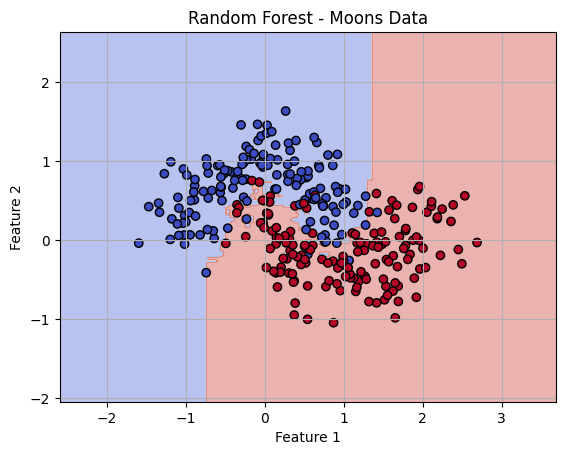

In [6]:
# Step 6: Plot decision boundary
h = 0.02
x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.4, cmap='coolwarm')
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm')
plt.title("Random Forest - Moons Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.savefig("output/Exp7_random_forest_decision_boundary.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusion
The Random Forest algorithm classified the nonlinear moons data with a curved decision boundary. Ensemble methods like Random Forest improve prediction accuracy and robustness by aggregating multiple decision trees.